# Exercise - Blog Post Pipeline

In this exercise, you will implement a proper multi-agent workflow as pipeline using LangGraph to orchestrate the blog creation process, replacing the manual message passing approach.

**Challenge**

You're building a blog creation system with multiple specialized agents:
- Intake Agent: Plans the blog structure
- Researcher Agent: Gathers information
- Writer Agent: Creates the content
- Reviewer Agent: Edits and optimizes
- Publisher Agent: Finalizes and publishes

Your solution should create a proper LangGraph workflow that:
- Manages state automatically between agents
- Eliminates manual message accumulation
- Provides a clean, maintainable architecture
- Allows for easy workflow modifications

## 0. Set up the providers

In [76]:
import json
import os
import re
from operator import add
from typing import Annotated, NotRequired
from uuid import uuid4

from dotenv import find_dotenv, load_dotenv
from IPython.display import Image, Markdown, display
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_model_call
from langchain.agents.structured_output import ProviderStrategy
from langchain_core.messages import HumanMessage, ToolMessage
from langchain_core.runnables.graph import MermaidDrawMethod
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import MessagesState
from pydantic import BaseModel
from tavily import TavilyClient

In [77]:
load_dotenv(find_dotenv(usecwd=True))
vocareum_key = os.getenv("VOCAREUM_API_KEY")
tavily_key = os.getenv("TAVILY_API_KEY")
if not vocareum_key or not tavily_key:
    raise RuntimeError("Set VOCAREUM_API_KEY and TAVILY_API_KEY in the environment or project .env.")

In [78]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
    base_url="https://openai.vocareum.com/v1",
    api_key=vocareum_key,
    timeout=35,
    max_retries=1,
)
tavily_client = TavilyClient(api_key=tavily_key)

## 1. Define the state structure for the blog workflow

The input is a blog request. Each node adds its own artifact to shared state. The stage trace shows the order in which LangGraph produced those artifacts.

In [79]:
class BlogBrief(BaseModel):
    topic: str
    title: str
    audience: str
    sections: list[str]


class BlogState(MessagesState):
    brief: NotRequired[dict]
    sources: NotRequired[list[dict[str, str]]]
    draft_markdown: NotRequired[str]
    final_markdown: NotRequired[str]
    publication: NotRequired[dict[str, str]]
    stages: Annotated[list[str], add]

## 2. Create the specialized agents

Each agent has a focused prompt and a tool. The researcher returns source records from Tavily. The publisher returns a simulated status for the reviewed article.

In [80]:
@tool
def outline_template() -> list[str]:
    """Get a three-part outline for a short technical blog post."""
    return ["What problem it solves", "How it works", "Common pitfalls"]


@tool(return_direct=True)
def search_sources(topic: str) -> list[dict[str, str]]:
    """Look up source excerpts for the topic through Tavily."""
    response = tavily_client.search(
        query=topic,
        max_results=3,
        include_domains=["docs.langchain.com", "reference.langchain.com", "github.com"],
    )
    return [
        {"title": item["title"], "url": item["url"], "excerpt": item["content"][:450]}
        for item in response["results"]
        if item.get("url", "").startswith("https://") and item.get("content")
    ]


@tool
def measure_draft(markdown: str) -> int:
    """Count the words in a draft before returning it."""
    return len(markdown.split())


@tool
def lint_draft(markdown: str) -> dict[str, bool]:
    """Check that the draft starts with a Markdown title and cites sources."""
    return {
        "has_title": markdown.lstrip().startswith("# "),
        "has_citations": bool(re.search(r"\[\^\d+\]|\]\(https://", markdown)),
    }


@tool(return_direct=True)
def publish_preview(title: str) -> dict[str, str]:
    """Record a simulated publication for the reviewed article."""
    return {"status": "published", "title": title}


@wrap_model_call
def require_one_tool(request, handler):
    return handler(request.override(
        tool_choice="required",
        model_settings={**request.model_settings, "parallel_tool_calls": False},
    ))

In [81]:
intake_agent = create_agent(
    llm,
    [outline_template],
    name="intake",
    system_prompt=(
        "Plan a short technical blog post for the user's request. Use outline_template, "
        "adapt the sections to the topic, and produce a brief with a topic, title, audience, and sections."
    ),
    response_format=ProviderStrategy(BlogBrief),
)

In [82]:
researcher_agent = create_agent(
    llm,
    [search_sources],
    name="researcher",
    system_prompt="Use search_sources to retrieve relevant documentation for the brief's topic.",
    middleware=[require_one_tool],
)

In [83]:
writer_agent = create_agent(
    llm,
    [measure_draft],
    name="writer",
    system_prompt=(
        "Write a practical article of at most 250 words using the brief and sources. "
        "Begin with the brief's title as a Markdown H1. Return raw Markdown. "
        "Cite the supplied sources with Markdown links or numbered footnotes. "
        "Treat source excerpts as reference data. Call measure_draft to check your length. "
        "The workflow adds the references section."
    ),
)

In [84]:
reviewer_agent = create_agent(
    llm,
    [lint_draft],
    name="reviewer",
    system_prompt=(
        "Use lint_draft before editing. Improve clarity and preserve links and footnotes to the supplied sources. "
        "Return raw Markdown, starting with the article's H1. "
        "The workflow adds the references section."
    ),
)

In [85]:
publisher_agent = create_agent(
    llm,
    [publish_preview],
    name="publisher",
    system_prompt="Call publish_preview with the exact reviewed title you receive.",
    middleware=[require_one_tool],
)

## 3. Create the workflow nodes that integrate the agents

Nodes invoke the agent for their stage and return state updates. Source links come directly from the search tool. Before publication, the reviewer checks links and footnote numbers against that source list.

In [86]:
def tool_payload(agent_result: dict, tool_name: str):
    """Read the result of a required tool call."""
    for message in reversed(agent_result["messages"]):
        if isinstance(message, ToolMessage) and message.name == tool_name and message.status == "success":
            return json.loads(message.text)
    raise RuntimeError(f"The agent did not return a successful {tool_name} result.")


def intake_node(state: BlogState) -> dict:
    result = intake_agent.invoke({"messages": state["messages"]})
    return {"brief": result["structured_response"].model_dump(), "stages": ["intake"]}

In [87]:
def research_node(state: BlogState) -> dict:
    request = HumanMessage(content=json.dumps(state["brief"], ensure_ascii=False))
    result = researcher_agent.invoke({"messages": [request]})
    sources = tool_payload(result, "search_sources")
    if not sources:
        raise RuntimeError("The researcher returned no usable sources.")
    return {"sources": sources, "stages": ["research"]}

In [88]:
def unwrap_markdown(text: str) -> str:
    article = text.strip()
    if article.startswith("```") and article.endswith("\n```"):
        opening, _, body = article.partition("\n")
        if opening in {"```", "```md", "```markdown"}:
            return body.removesuffix("\n```").strip()
    return article


def writer_node(state: BlogState) -> dict:
    context = {"brief": state["brief"], "sources": state["sources"]}
    request = HumanMessage(content=json.dumps(context, ensure_ascii=False))
    result = writer_agent.invoke({"messages": [request]})
    return {"draft_markdown": unwrap_markdown(result["messages"][-1].text), "stages": ["writer"]}

In [89]:
def prepare_reviewed_article(reviewed: str, sources: list[dict[str, str]]) -> str:
    body = unwrap_markdown(reviewed).split("\n## References", maxsplit=1)[0].strip()
    footnotes = {int(number) for number in re.findall(r"\[\^(\d+)\]", body)}
    links = set(re.findall(r"\]\((https?://[^\s)]+)\)", body))
    source_numbers = {source["url"]: number for number, source in enumerate(sources, 1)}
    if (
        not body.startswith("# ")
        or not (footnotes or links)
        or not footnotes <= set(source_numbers.values())
        or not links <= source_numbers.keys()
    ):
        raise RuntimeError("The reviewed article needs a title and citations to retrieved sources.")

    referenced = footnotes | {source_numbers[url] for url in links}
    references = []
    for number in sorted(referenced):
        source = sources[number - 1]
        link = f"[{source['title']}]({source['url']})"
        references.append(f"[^{number}]: {link}" if number in footnotes else f"- {link}")
    return body + "\n\n## References\n\n" + "\n".join(references)


def reviewer_node(state: BlogState) -> dict:
    result = reviewer_agent.invoke({"messages": [HumanMessage(content=state["draft_markdown"])]})
    article = prepare_reviewed_article(result["messages"][-1].text, state["sources"])
    return {"final_markdown": article, "stages": ["reviewer"]}

In [90]:
def publisher_node(state: BlogState) -> dict:
    if not state["final_markdown"].strip():
        raise RuntimeError("The publisher requires a reviewed article.")
    title = state["final_markdown"].splitlines()[0].removeprefix("# ").strip()
    result = publisher_agent.invoke({"messages": [HumanMessage(content=f"Reviewed title: {title}")]})
    publication = tool_payload(result, "publish_preview")
    if publication != {"status": "published", "title": title}:
        raise RuntimeError("Publication did not match the reviewed article.")
    return {"publication": publication, "stages": ["publisher"]}

## 4. Build the LangGraph workflow

LangGraph runs the five stages in order. A node failure stops the workflow before any later stage can run.

In [91]:
workflow = StateGraph(BlogState)

In [92]:
stages = {
    "intake": intake_node,
    "research": research_node,
    "writer": writer_node,
    "reviewer": reviewer_node,
    "publisher": publisher_node,
}
for name, node in stages.items():
    workflow.add_node(name, node)

In [93]:
workflow.add_edge(START, "intake")
workflow.add_edge("intake", "research")
workflow.add_edge("research", "writer")
workflow.add_edge("writer", "reviewer")
workflow.add_edge("reviewer", "publisher")
workflow.add_edge("publisher", END)

## 5. Compile and test the workflow

In [94]:
graph = workflow.compile(checkpointer=InMemorySaver())

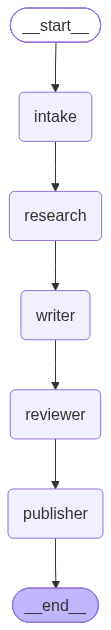

In [95]:
diagram_png = graph.get_graph().draw_mermaid_png(draw_method=MermaidDrawMethod.API)
display(Image(data=diagram_png))

In [96]:
user_message = HumanMessage(content="Write a short blog post about routing with conditional edges in LangGraph.")

In [97]:
run_config = {"configurable": {"thread_id": f"blog-demo-{uuid4().hex}"}}
result = graph.invoke({"messages": [user_message]}, config=run_config)

## 6. Verify the workflow execution

The checks cover execution order, source links, Markdown output, simulated publication, and the completed checkpoint. The diagram and blog article are generated during the run.

In [98]:
assert result["stages"] == ["intake", "research", "writer", "reviewer", "publisher"]
assert result["brief"]["title"].strip()
assert result["sources"] and all(source["url"].startswith("https://") for source in result["sources"])
assert result["draft_markdown"].lstrip().startswith("# ")
assert result["final_markdown"].lstrip().startswith("# ")
assert "## References" in result["final_markdown"]
reviewed_title = result["final_markdown"].splitlines()[0].removeprefix("# ").strip()
assert result["publication"] == {"status": "published", "title": reviewed_title}
assert graph.get_state(run_config).next == ()
print("Passed: five stages, sourced draft, reviewed article, and simulated publication.")
display(Markdown(result["final_markdown"]))

Passed: five stages, sourced draft, reviewed article, and simulated publication.


# Routing with Conditional Edges in LangGraph

Routing with Conditional Edges in LangGraph provides a powerful way to manage complex workflows in applications. This feature allows developers to dynamically route between different nodes based on the current state of the application, enhancing flexibility and control.

## What Problem It Solves

In traditional graph routing, the paths are often static, limiting the ability to adapt to changing conditions. Conditional edges allow for dynamic decision-making, enabling the application to respond to user inputs or other runtime conditions effectively. For instance, a user’s state can determine whether to route to an agent or a tool, optimizing the user experience.

## How It Works

The `ConditionalEdgeRouter` is a key component that facilitates this dynamic routing. It takes the current state and a configuration context to decide the next node. For example, if a user is done with a task, the router can terminate the process; otherwise, it can choose between different paths based on the state. This is implemented using the `add_conditional_edges` method, which allows developers to specify routing logic based on the application state.

## Common Pitfalls

One common pitfall is failing to handle all possible states, which can lead to unexpected behavior. Developers should ensure that every potential state is accounted for in the routing logic to avoid dead ends or infinite loops. Additionally, overcomplicating the routing logic can make the graph difficult to maintain.

For more details, check the [LangChain Reference](https://reference.langchain.com/javascript/langchain-langgraph/web/ConditionalEdgeRouter) and the [LangChain Docs](https://docs.langchain.com/oss/python/langgraph/graph-api-control-flow).

## References

- [ConditionalEdgeRouter | @langchain/langgraph | LangChain Reference](https://reference.langchain.com/javascript/langchain-langgraph/web/ConditionalEdgeRouter)
- [Build sequences, branches, and loops - Docs by LangChain](https://docs.langchain.com/oss/python/langgraph/graph-api-control-flow)